In [77]:
import pandas as pd, numpy as np, requests, io, time, os
import matplotlib.pyplot as plt

BASE = "https://earthquake.usgs.gov/fdsnws/event/1/query"
os.makedirs("data/raw", exist_ok=True)
os.makedirs("data/processed", exist_ok=True)
DOSYA = "data/raw/usgs_turkiye_1996_2026.csv"

def cek(baslangic, bitis):
    p = dict(format="csv", starttime=baslangic, endtime=bitis,
             minlatitude=35.5, maxlatitude=42.5,
             minlongitude=25.5, maxlongitude=45,
             minmagnitude=2, eventtype="earthquake", orderby="time-asc")
    r = requests.get(BASE, params=p, timeout=120)
    if r.status_code == 400:          # 20.000 sınırı aşıldı olabilir
        return None
    r.raise_for_status()
    return pd.read_csv(io.StringIO(r.text))

if os.path.exists(DOSYA):
    ham = pd.read_csv(DOSYA)
    print("Dosya zaten var, indirme atlandı:", len(ham), "satır")
else:
    parcalar = []
    for yil in range(1996, 2027):
        df_ = cek(f"{yil}-01-01", f"{yil+1}-01-01")
        if df_ is None:               # yılı aylara böl
            aylik = []
            for ay in range(1, 13):
                b = f"{yil}-{ay:02d}-01"
                s = f"{yil+1}-01-01" if ay == 12 else f"{yil}-{ay+1:02d}-01"
                aylik.append(cek(b, s))
                time.sleep(0.5)
            df_ = pd.concat(aylik, ignore_index=True)
        print(yil, len(df_))
        parcalar.append(df_)
        time.sleep(1)
    ham = pd.concat(parcalar, ignore_index=True).drop_duplicates("id")
    ham.to_csv(DOSYA, index=False)
    print("Toplam satır:", len(ham))

Dosya zaten var, indirme atlandı: 12788 satır


In [78]:
print(ham.shape)
print(ham.columns.tolist())
print(ham["time"].min(), ham["time"].max())
print(ham["mag"].describe())

(12788, 22)
['time', 'latitude', 'longitude', 'depth', 'mag', 'magType', 'nst', 'gap', 'dmin', 'rms', 'net', 'id', 'updated', 'place', 'type', 'horizontalError', 'depthError', 'magError', 'magNst', 'status', 'locationSource', 'magSource']
1996-01-01T16:05:29.550Z 2026-10-04T22:51:31.153Z
count    12788.000000
mean         3.594026
std          0.680086
min          2.100000
25%          3.100000
50%          3.500000
75%          4.100000
max          7.800000
Name: mag, dtype: float64


In [79]:
df = ham.copy()
df["time"] = pd.to_datetime(df["time"], utc=True)
df["yil"] = df["time"].dt.year
df = df[df["mag"].notna()]

turkiye = df["place"].str.contains("Turkey|Türkiye|Turkiye|Kahramanmaras", na=False)
dis = df[~turkiye]
df = df[turkiye].copy()

print("Kalan (Türkiye):", len(df), "| Elenen:", len(dis))
print(dis["place"].str.extract(r",\s*([^,]+)$")[0].value_counts().head(15))
print("En büyük deprem:", df["mag"].max())
print(df[["time","yil","mag","place"]].head())

Kalan (Türkiye): 9317 | Elenen: 3471
0
Greece        3204
Iran            56
Georgia         43
Armenia         35
Iraq            29
Cyprus          28
Syria           26
Bulgaria        22
Azerbaijan       3
Name: count, dtype: int64
En büyük deprem: 7.8
                              time   yil  mag                         place
0 1996-01-01 16:05:29.550000+00:00  1996  4.0    21 km SSE of Milas, Turkey
1 1996-01-01 19:01:32.780000+00:00  1996  2.8   23 km ESE of Kumba?, Turkey
2 1996-01-02 03:55:23.410000+00:00  1996  2.6  25 km SSE of Malkara, Turkey
3 1996-01-02 07:58:51.140000+00:00  1996  2.5      8 km WSW of Soma, Turkey
4 1996-01-02 08:51:25.940000+00:00  1996  2.7  3 km NNW of K?rka?aç, Turkey


In [80]:
yillik = pd.DataFrame({
    f"M{e}+": df[df.mag >= e].groupby("yil").size()
    for e in [2, 3, 4, 5]
}).fillna(0).astype(int)
print(yillik.to_string())

       M2+  M3+  M4+  M5+
yil                      
1996   418  199   28    3
1997   251  140   36    4
1998  1060  387   57    5
1999  1295  672  181   18
2000   275  225   63    7
2001   368  210   53    4
2002   135  130   50    4
2003   230  215   66   10
2004   774  527   85   10
2005  1028  920  125   18
2006   552  435   50    2
2007   478  444   88    9
2008   334  327   66    4
2009    30   30   29    4
2010    48   48   47    7
2011   230  230  229   20
2012   108  108  108    8
2013    62   62   57    3
2014    82   82   75    2
2015    60   60   53    4
2016    42   42   38    2
2017    90   90   88   11
2018    52   51   50    4
2019    81   81   75    6
2020   147  147  144   18
2021    56   56   54    4
2022    80   80   79    7
2023   657  655  642   44
2024   105  104   97    6
2025   137  137  132   12
2026    52   52   51    7


In [81]:
df["m4alti"] = df["mag"] < 4
print("Her yıl M4 altı depremlerin oranı:")
print(df.groupby("yil")["m4alti"].mean().round(2).to_string())
print()
print("Ağ (net) dağılımı:")
print(df.groupby("yil")["net"].agg(lambda s: s.value_counts().head(3).to_dict()).to_string())
print()
print("Büyüklük kaynağı (magSource):")
print(df.groupby("yil")["magSource"].agg(lambda s: s.value_counts().head(3).to_dict()).to_string())

Her yıl M4 altı depremlerin oranı:
yil
1996    0.93
1997    0.86
1998    0.95
1999    0.86
2000    0.77
2001    0.86
2002    0.63
2003    0.71
2004    0.89
2005    0.88
2006    0.91
2007    0.82
2008    0.80
2009    0.03
2010    0.02
2011    0.00
2012    0.00
2013    0.08
2014    0.09
2015    0.12
2016    0.10
2017    0.02
2018    0.04
2019    0.07
2020    0.02
2021    0.04
2022    0.01
2023    0.02
2024    0.08
2025    0.04
2026    0.02

Ağ (net) dağılımı:
yil
1996     {'us': 418}
1997     {'us': 251}
1998    {'us': 1060}
1999    {'us': 1295}
2000     {'us': 275}
2001     {'us': 368}
2002     {'us': 135}
2003     {'us': 230}
2004     {'us': 774}
2005    {'us': 1028}
2006     {'us': 552}
2007     {'us': 478}
2008     {'us': 334}
2009      {'us': 30}
2010      {'us': 48}
2011     {'us': 230}
2012     {'us': 108}
2013      {'us': 62}
2014      {'us': 82}
2015      {'us': 60}
2016      {'us': 42}
2017      {'us': 90}
2018      {'us': 52}
2019      {'us': 81}
2020     {'us': 147}
2021     

In [82]:
def mc(m):
    h, kenar = np.histogram(m, bins=np.arange(1.95, 7.05, 0.1))
    return round(kenar[h.argmax()] + 0.05, 1)

mc_yil = df.groupby("yil")["mag"].apply(mc)
print(mc_yil.to_string())

yil
1996    2.7
1997    2.7
1998    2.7
1999    2.8
2000    3.0
2001    2.8
2002    3.9
2003    3.4
2004    3.2
2005    3.2
2006    2.9
2007    3.4
2008    3.3
2009    4.5
2010    4.0
2011    4.2
2012    4.2
2013    4.0
2014    4.1
2015    4.0
2016    4.2
2017    4.1
2018    4.3
2019    4.3
2020    4.2
2021    4.1
2022    4.2
2023    4.3
2024    4.1
2025    4.4
2026    4.2


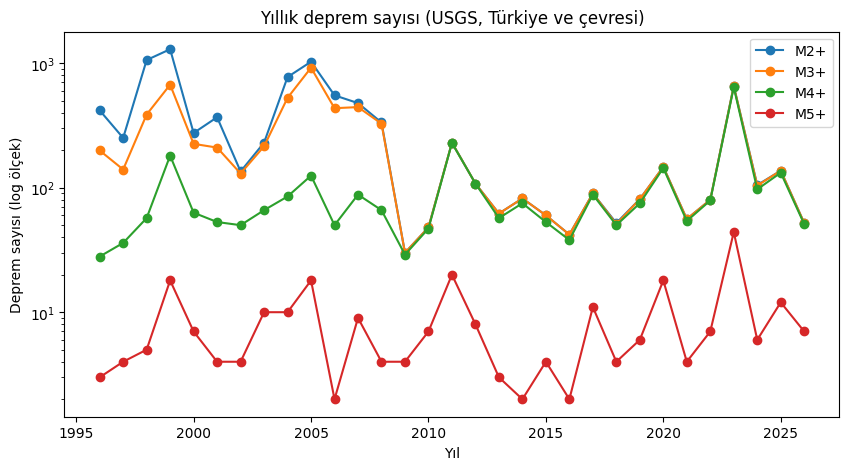

In [83]:
yillik.plot(figsize=(10, 5), logy=True, marker="o")
plt.title("Yıllık deprem sayısı (USGS, Türkiye ve çevresi)")
plt.ylabel("Deprem sayısı (log ölçek)")
plt.xlabel("Yıl")
plt.show()

In [84]:
yillik.to_csv("data/processed/yillik_sayilar_usgs.csv")
mc_yil.to_csv("data/processed/mc_yillik_usgs.csv")
df.drop(columns=["m4alti"]).to_csv("data/processed/usgs_temiz.csv", index=False)

from google.colab import files
files.download("data/processed/yillik_sayilar_usgs.csv")
files.download("data/processed/mc_yillik_usgs.csv")
files.download("data/processed/usgs_temiz.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [85]:
from google.colab import files
files.download("data/processed/yillik_sayilar_usgs.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [86]:
df["bolgesel"] = df["magSource"].isin(["isk", "ath", "the"])
kaynak = df.groupby("yil").agg(toplam=("mag", "size"), bolgesel=("bolgesel", "sum"))
kaynak["bolgesel_oran"] = (kaynak["bolgesel"] / kaynak["toplam"]).round(3)
print(kaynak.to_string())
kaynak.to_csv("data/processed/kaynak_pay_usgs.csv")

      toplam  bolgesel  bolgesel_oran
yil                                  
1996     418       349          0.835
1997     251       208          0.829
1998    1060       989          0.933
1999    1295      1067          0.824
2000     275       165          0.600
2001     368       306          0.832
2002     135        66          0.489
2003     230       159          0.691
2004     774       669          0.864
2005    1028       926          0.901
2006     552       505          0.915
2007     478       398          0.833
2008     334       285          0.853
2009      30         5          0.167
2010      48        10          0.208
2011     230        18          0.078
2012     108        14          0.130
2013      62         9          0.145
2014      82         6          0.073
2015      60         5          0.083
2016      42         5          0.119
2017      90         0          0.000
2018      52         0          0.000
2019      81         0          0.000
2020     147

In [87]:
import os
print("Klasördeki dosyalar:")
print([f for f in os.listdir(".") if not f.startswith(".")])
print()

adaylar = [f for f in os.listdir(".") if f.lower().endswith((".csv", ".xlsx", ".xls"))]
print("CSV/Excel dosyaları:", adaylar)

Klasördeki dosyalar:
['site', 'data', 'afad_m4_1996_2026.csv', 'sample_data']

CSV/Excel dosyaları: ['afad_m4_1996_2026.csv']


In [88]:
import os

DOSYA = "afad_m4_1996_2026.csv"

print("Dosya var mı:", os.path.exists(DOSYA))
if not os.path.exists(DOSYA):
    print("Klasördeki dosyalar:", [f for f in os.listdir(".") if not f.startswith(".")])
else:
    print("Boyut (bayt):", os.path.getsize(DOSYA))
    with open(DOSYA, "rb") as f:
        print(f.read(500))

Dosya var mı: True
Boyut (bayt): 835107
b'\xef\xbb\xbfDate,Longitude,Latitude,Depth,Type,Magnitude,Location,EventID,TimeName,TypeName,MagnitudeName\r\n"05/10/2026 01:51:29",36.0965,37.7583,7,"MW",4.1,"Saimbeyli (Adana)",730440,"AFAD","AFAD","AFAD"\r\n"04/10/2026 20:28:12",36.0938,37.7638,7,"MW",4.3,"Saimbeyli (Adana)",730402,"AFAD","AFAD","AFAD"\r\n"04/10/2026 19:00:24",36.0977,37.7667,7,"MW",4.4,"Saimbeyli (Adana)",730394,"AFAD","AFAD","AFAD"\r\n"04/10/2026 14:43:21",36.1008,37.7417,7,"MW",5.2,"Saimbeyli (Adana)",730349,"AFAD","AFAD","AFAD"\r\n"04/10/202'


In [89]:
DOSYA = "afad_m4_1996_2026.csv"

afad = None
for sep in [",", ";", "\t"]:
    for enc in ["utf-8-sig", "cp1254", "latin-1"]:
        try:
            d = pd.read_csv(DOSYA, sep=sep, encoding=enc)
            print(f"sep={sep!r} enc={enc} -> {d.shape}")
            if d.shape[1] > 3 and afad is None:
                afad, ayar = d, (sep, enc)
        except Exception as e:
            print(f"sep={sep!r} enc={enc} HATA: {str(e)[:80]}")

if afad is not None:
    print("\nSeçilen ayar:", ayar)
    print(afad.shape)
    print(afad.columns.tolist())
    print(afad.head().to_string())
    print()
    print(afad.dtypes)
else:
    print("\nHiçbir ayar tutmadı, ilk baytlara bak:")
    with open(DOSYA, "rb") as f:
        print(f.read(500))

sep=',' enc=utf-8-sig -> (8709, 11)
sep=',' enc=cp1254 HATA: 'charmap' codec can't decode byte 0x9e in position 1157: character maps to <unde
sep=',' enc=latin-1 -> (8709, 11)
sep=';' enc=utf-8-sig -> (8709, 1)
sep=';' enc=cp1254 HATA: 'charmap' codec can't decode byte 0x9e in position 1157: character maps to <unde
sep=';' enc=latin-1 -> (8709, 1)
sep='\t' enc=utf-8-sig -> (8709, 1)
sep='\t' enc=cp1254 HATA: 'charmap' codec can't decode byte 0x9e in position 1157: character maps to <unde
sep='\t' enc=latin-1 -> (8709, 1)

Seçilen ayar: (',', 'utf-8-sig')
(8709, 11)
['Date', 'Longitude', 'Latitude', 'Depth', 'Type', 'Magnitude', 'Location', 'EventID', 'TimeName', 'TypeName', 'MagnitudeName']
                  Date  Longitude  Latitude  Depth Type  Magnitude           Location  EventID TimeName TypeName MagnitudeName
0  05/10/2026 01:51:29    36.0965   37.7583   7.00   MW        4.1  Saimbeyli (Adana)   730440     AFAD     AFAD          AFAD
1  04/10/2026 20:28:12    36.0938   37.7638   

In [90]:
import pandas as pd, numpy as np

DOSYA = "afad_m4_1996_2026.csv"
afad = pd.read_csv(DOSYA, encoding="utf-8-sig")

print(afad.shape)
print(afad.columns.tolist())
print(afad.head().to_string())
print()
print(afad.dtypes)

afad["Date"] = pd.to_datetime(afad["Date"], errors="coerce")
afad["yil"] = afad["Date"].dt.year
print()
print("Tarih aralığı:", afad["Date"].min(), "->", afad["Date"].max())
print("Büyüklük:", afad["Magnitude"].min(), "-", afad["Magnitude"].max())
print()
print("Büyüklük türü (Type):")
print(afad["Type"].value_counts().head(10))
print()
print("Yer (Location) örnekleri:")
print(afad["Location"].sample(10, random_state=1).to_string())
print()
print("Yıllık M4+ ve M5+ (AFAD, tüm kayıtlar):")
print(pd.DataFrame({
    "M4+": afad.groupby("yil").size(),
    "M5+": afad[afad["Magnitude"] >= 5].groupby("yil").size(),
}).fillna(0).astype(int).to_string())

(8709, 11)
['Date', 'Longitude', 'Latitude', 'Depth', 'Type', 'Magnitude', 'Location', 'EventID', 'TimeName', 'TypeName', 'MagnitudeName']
                  Date  Longitude  Latitude  Depth Type  Magnitude           Location  EventID TimeName TypeName MagnitudeName
0  05/10/2026 01:51:29    36.0965   37.7583   7.00   MW        4.1  Saimbeyli (Adana)   730440     AFAD     AFAD          AFAD
1  04/10/2026 20:28:12    36.0938   37.7638   7.00   MW        4.3  Saimbeyli (Adana)   730402     AFAD     AFAD          AFAD
2  04/10/2026 19:00:24    36.0977   37.7667   7.00   MW        4.4  Saimbeyli (Adana)   730394     AFAD     AFAD          AFAD
3  04/10/2026 14:43:21    36.1008   37.7417   7.00   MW        5.2  Saimbeyli (Adana)   730349     AFAD     AFAD          AFAD
4  04/10/2026 14:36:24    36.1050   37.7607   8.67   MW        4.9  Saimbeyli (Adana)   730348     AFAD     AFAD          AFAD

Date              object
Longitude        float64
Latitude         float64
Depth            float6

In [91]:
import pandas as pd, numpy as np, os, io, time, requests

# 1) AFAD: tarih düzeltmesi (gün/ay/yıl)
afad = pd.read_csv("afad_m4_1996_2026.csv", encoding="utf-8-sig")
afad["Date"] = pd.to_datetime(afad["Date"], dayfirst=True, errors="coerce")
print("Okunamayan tarih:", afad["Date"].isna().sum())
print("Tarih aralığı:", afad["Date"].min(), "->", afad["Date"].max())
afad["yil"] = afad["Date"].dt.year
afad["Type"] = afad["Type"].str.upper()

kutu = afad["Latitude"].between(35.5, 42.5) & afad["Longitude"].between(25.5, 45)
afad_k = afad[kutu].copy()
print("AFAD toplam:", len(afad), "| koordinat kutusu içinde:", len(afad_k))

# 2) USGS ham veri (aynı kutu)
DOSYA_USGS = "data/raw/usgs_turkiye_1996_2026.csv"
if os.path.exists(DOSYA_USGS):
    usgs = pd.read_csv(DOSYA_USGS)
else:
    os.makedirs("data/raw", exist_ok=True)
    BASE = "https://earthquake.usgs.gov/fdsnws/event/1/query"
    parcalar = []
    for yil in range(1996, 2027):
        p = dict(format="csv", starttime=f"{yil}-01-01", endtime=f"{yil+1}-01-01",
                 minlatitude=35.5, maxlatitude=42.5, minlongitude=25.5, maxlongitude=45,
                 minmagnitude=2, eventtype="earthquake", orderby="time-asc")
        r = requests.get(BASE, params=p, timeout=120); r.raise_for_status()
        parcalar.append(pd.read_csv(io.StringIO(r.text))); time.sleep(1)
    usgs = pd.concat(parcalar, ignore_index=True).drop_duplicates("id")
    usgs.to_csv(DOSYA_USGS, index=False)

usgs["time"] = pd.to_datetime(usgs["time"], utc=True)
usgs["yil"] = usgs["time"].dt.year
usgs = usgs[usgs["mag"].notna()]

# 3) Karşılaştırma (2026 eksik yıl olduğu için 1996-2025)
def say(d, mag, esik):
    return d[d[mag] >= esik].groupby("yil").size()

kars = pd.DataFrame({
    "AFAD_M4+": say(afad_k, "Magnitude", 4),
    "USGS_M4+": say(usgs, "mag", 4),
    "AFAD_M5+": say(afad_k, "Magnitude", 5),
    "USGS_M5+": say(usgs, "mag", 5),
}).fillna(0).astype(int).loc[1996:2025]

print()
print(kars.to_string())
print()
print("Toplam:", kars.sum().to_dict())

os.makedirs("data/processed", exist_ok=True)
kars.to_csv("data/processed/karsilastirma_m4_m5.csv")

Okunamayan tarih: 0
Tarih aralığı: 1996-01-04 17:28:40 -> 2026-10-05 01:51:29
AFAD toplam: 8709 | koordinat kutusu içinde: 4797

      AFAD_M4+  USGS_M4+  AFAD_M5+  USGS_M5+
yil                                         
1996       158        81         8         8
1997        86        66         5         5
1998        83        72         6         6
1999       247       195        15        18
2000        87        76         5         7
2001       107        79         6         7
2002        98        67         6         6
2003       112        87        11        11
2004       123       117        12        12
2005       173       147        17        18
2006        79        70         2         2
2007       139       121        11        11
2008       125       104         5         5
2009        80        42         6         7
2010       100        58         8         8
2011       313       255        23        23
2012       186       131        11        12
2013       101  

In [92]:
u25 = usgs[(usgs["yil"] == 2025) & (usgs["mag"] >= 4)]
print("USGS 2025 M4+ ülke dağılımı:")
print(u25["place"].str.extract(r",\s*([^,]+)$")[0].value_counts().head(8))
print()
a25 = afad_k[(afad_k["yil"] == 2025) & (afad_k["Magnitude"] >= 4)]
print("AFAD 2025 M4+ yer örnekleri:")
print(a25["Location"].value_counts().head(8))

from google.colab import files
files.download("data/processed/karsilastirma_m4_m5.csv")

USGS 2025 M4+ ülke dağılımı:
0
Greece     368
Turkey     132
Armenia      2
Syria        1
Name: count, dtype: int64

AFAD 2025 M4+ yer örnekleri:
Location
Ege Denizi                143
Sındırgı (Balıkesir)       84
Simav (Kütahya)            14
Kulu (Konya)                3
Göksun (Kahramanmaraş)      2
Gemlik (Bursa)              2
Gümüşhacıköy (Amasya)       2
Tuşba (Van)                 2
Name: count, dtype: int64


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [94]:
import pandas as pd, numpy as np, os, glob
os.makedirs("site/data", exist_ok=True)

yol = "data/raw/usgs_turkiye_1996_2026.csv"
if not os.path.exists(yol):
    print("Ham dosya bulunamadı, bulunanlar:", glob.glob("**/*usgs*", recursive=True))
    raise SystemExit
t = pd.read_csv(yol)
print("Sütunlar:", t.columns.tolist(), "| satır:", len(t))

t = t[t["place"].str.contains("Turkey|Türkiye|Turkiye|Kahramanmaras", na=False)].copy()
t["yil"] = pd.to_datetime(t["time"], utc=True).dt.year
t = t[t["yil"].between(1996, 2025)]
t["bolgesel"] = t["magSource"].isin(["isk", "ath", "the"])

def mc(m):
    h = np.histogram(m.dropna(), bins=np.arange(1.0, 8.05, 0.1))
    return round(float(h[1][h[0].argmax()]), 1)

g = t.groupby("yil")
yillik = pd.DataFrame({
    "toplam": g.size(),
    "m4_alti": g["mag"].apply(lambda s: (s < 4).sum()),
    "m4_ustu": g["mag"].apply(lambda s: (s >= 4).sum()),
    "m5_ustu": g["mag"].apply(lambda s: (s >= 5).sum()),
    "mc": g["mag"].apply(mc),
    "bolgesel_pay": g["bolgesel"].mean().round(3),
}).reset_index()
yillik.to_csv("site/data/usgs_yillik.csv", index=False)
kars.to_csv("site/data/karsilastirma_m4_m5.csv")
print(yillik.head(), yillik.shape)

Sütunlar: ['time', 'latitude', 'longitude', 'depth', 'mag', 'magType', 'nst', 'gap', 'dmin', 'rms', 'net', 'id', 'updated', 'place', 'type', 'horizontalError', 'depthError', 'magError', 'magNst', 'status', 'locationSource', 'magSource'] | satır: 12788
    yil  toplam  m4_alti  m4_ustu  m5_ustu   mc  bolgesel_pay
0  1996     418      390       28        3  2.6         0.835
1  1997     251      215       36        4  2.6         0.829
2  1998    1060     1003       57        5  2.6         0.933
3  1999    1295     1114      181       18  2.7         0.824
4  2000     275      212       63        7  2.9         0.600 (30, 7)


In [ ]:
import glob, os, shutil
print("Çalışma klasörü:", os.getcwd())
bulunan = glob.glob("/content/**/*afad*", recursive=True)
print("AFAD diye bulunanlar:", bulunan)
adaylar = [f for f in bulunan if f.lower().endswith(".csv")]
if adaylar:
    shutil.copy(adaylar[0], "/content/afad_m4_1996_2026.csv")
    print("Kopyalandı ->", "/content/afad_m4_1996_2026.csv", os.path.getsize("/content/afad_m4_1996_2026.csv"), "bayt")
else:
    print("CSV bulunamadı, dosya henüz yüklenmemiş")